<span style="color:cyan;font-size:30px"><b> IBM HR Attrition Prediction

# Loading Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Data Loading and Preview

In [2]:
df = pd.read_csv("IBM_HR_Attrition_Enhanced.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeGroup,TenureGroup,MonthlyIncomeBracket,OverallSatisfactionIndex
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,0,1,6,4,0,5,35-44,Established (6-10 yrs),High,2.00
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,3,3,10,7,1,7,45-54,Established (6-10 yrs),High,3.00
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,3,3,0,0,0,0,35-44,New (0-2 yrs),Low,3.00
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,3,8,7,3,0,25-34,Established (6-10 yrs),Low,3.25
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,3,3,2,2,2,2,25-34,New (0-2 yrs),Medium,2.50


## shape

In [3]:
df.shape

(1470, 39)

## data types and info

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 39 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1470 non-null   int64  
 1   Attrition                 1470 non-null   object 
 2   BusinessTravel            1470 non-null   object 
 3   DailyRate                 1470 non-null   int64  
 4   Department                1470 non-null   object 
 5   DistanceFromHome          1470 non-null   int64  
 6   Education                 1470 non-null   int64  
 7   EducationField            1470 non-null   object 
 8   EmployeeCount             1470 non-null   int64  
 9   EmployeeNumber            1470 non-null   int64  
 10  EnvironmentSatisfaction   1470 non-null   int64  
 11  Gender                    1470 non-null   object 
 12  HourlyRate                1470 non-null   int64  
 13  JobInvolvement            1470 non-null   int64  
 14  JobLevel

## variable summary

In [5]:
pd.options.display.max_columns = 27
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,OverallSatisfactionIndex
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129,2.730952
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136,0.505815
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000,2.500000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000,2.750000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000,3.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000,4.000000


* drop `EmployeeCount` `EmplyeeNumber` `StandardHours`

In [6]:
df.describe(include='object')

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime,AgeGroup,TenureGroup,MonthlyIncomeBracket
count,1470,1470,1470,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2,5,4,4
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No,25-34,Established (6-10 yrs),Low
freq,1233,1043,961,606,882,326,673,1470,1054,554,448,369


* drop `Over18` 

# Data Preprocessing

## duplicates

In [7]:
df['EmployeeNumber'].duplicated().sum()

np.int64(0)

## dropping columns

In [8]:
df.drop(columns=['EmployeeCount', 'EmployeeNumber', 'StandardHours', 'Over18'], inplace=True)

## data balance

In [9]:
df['Attrition'].value_counts()[::-1]

Attrition
Yes     237
No     1233
Name: count, dtype: int64

## univariate visualization

### variable counts

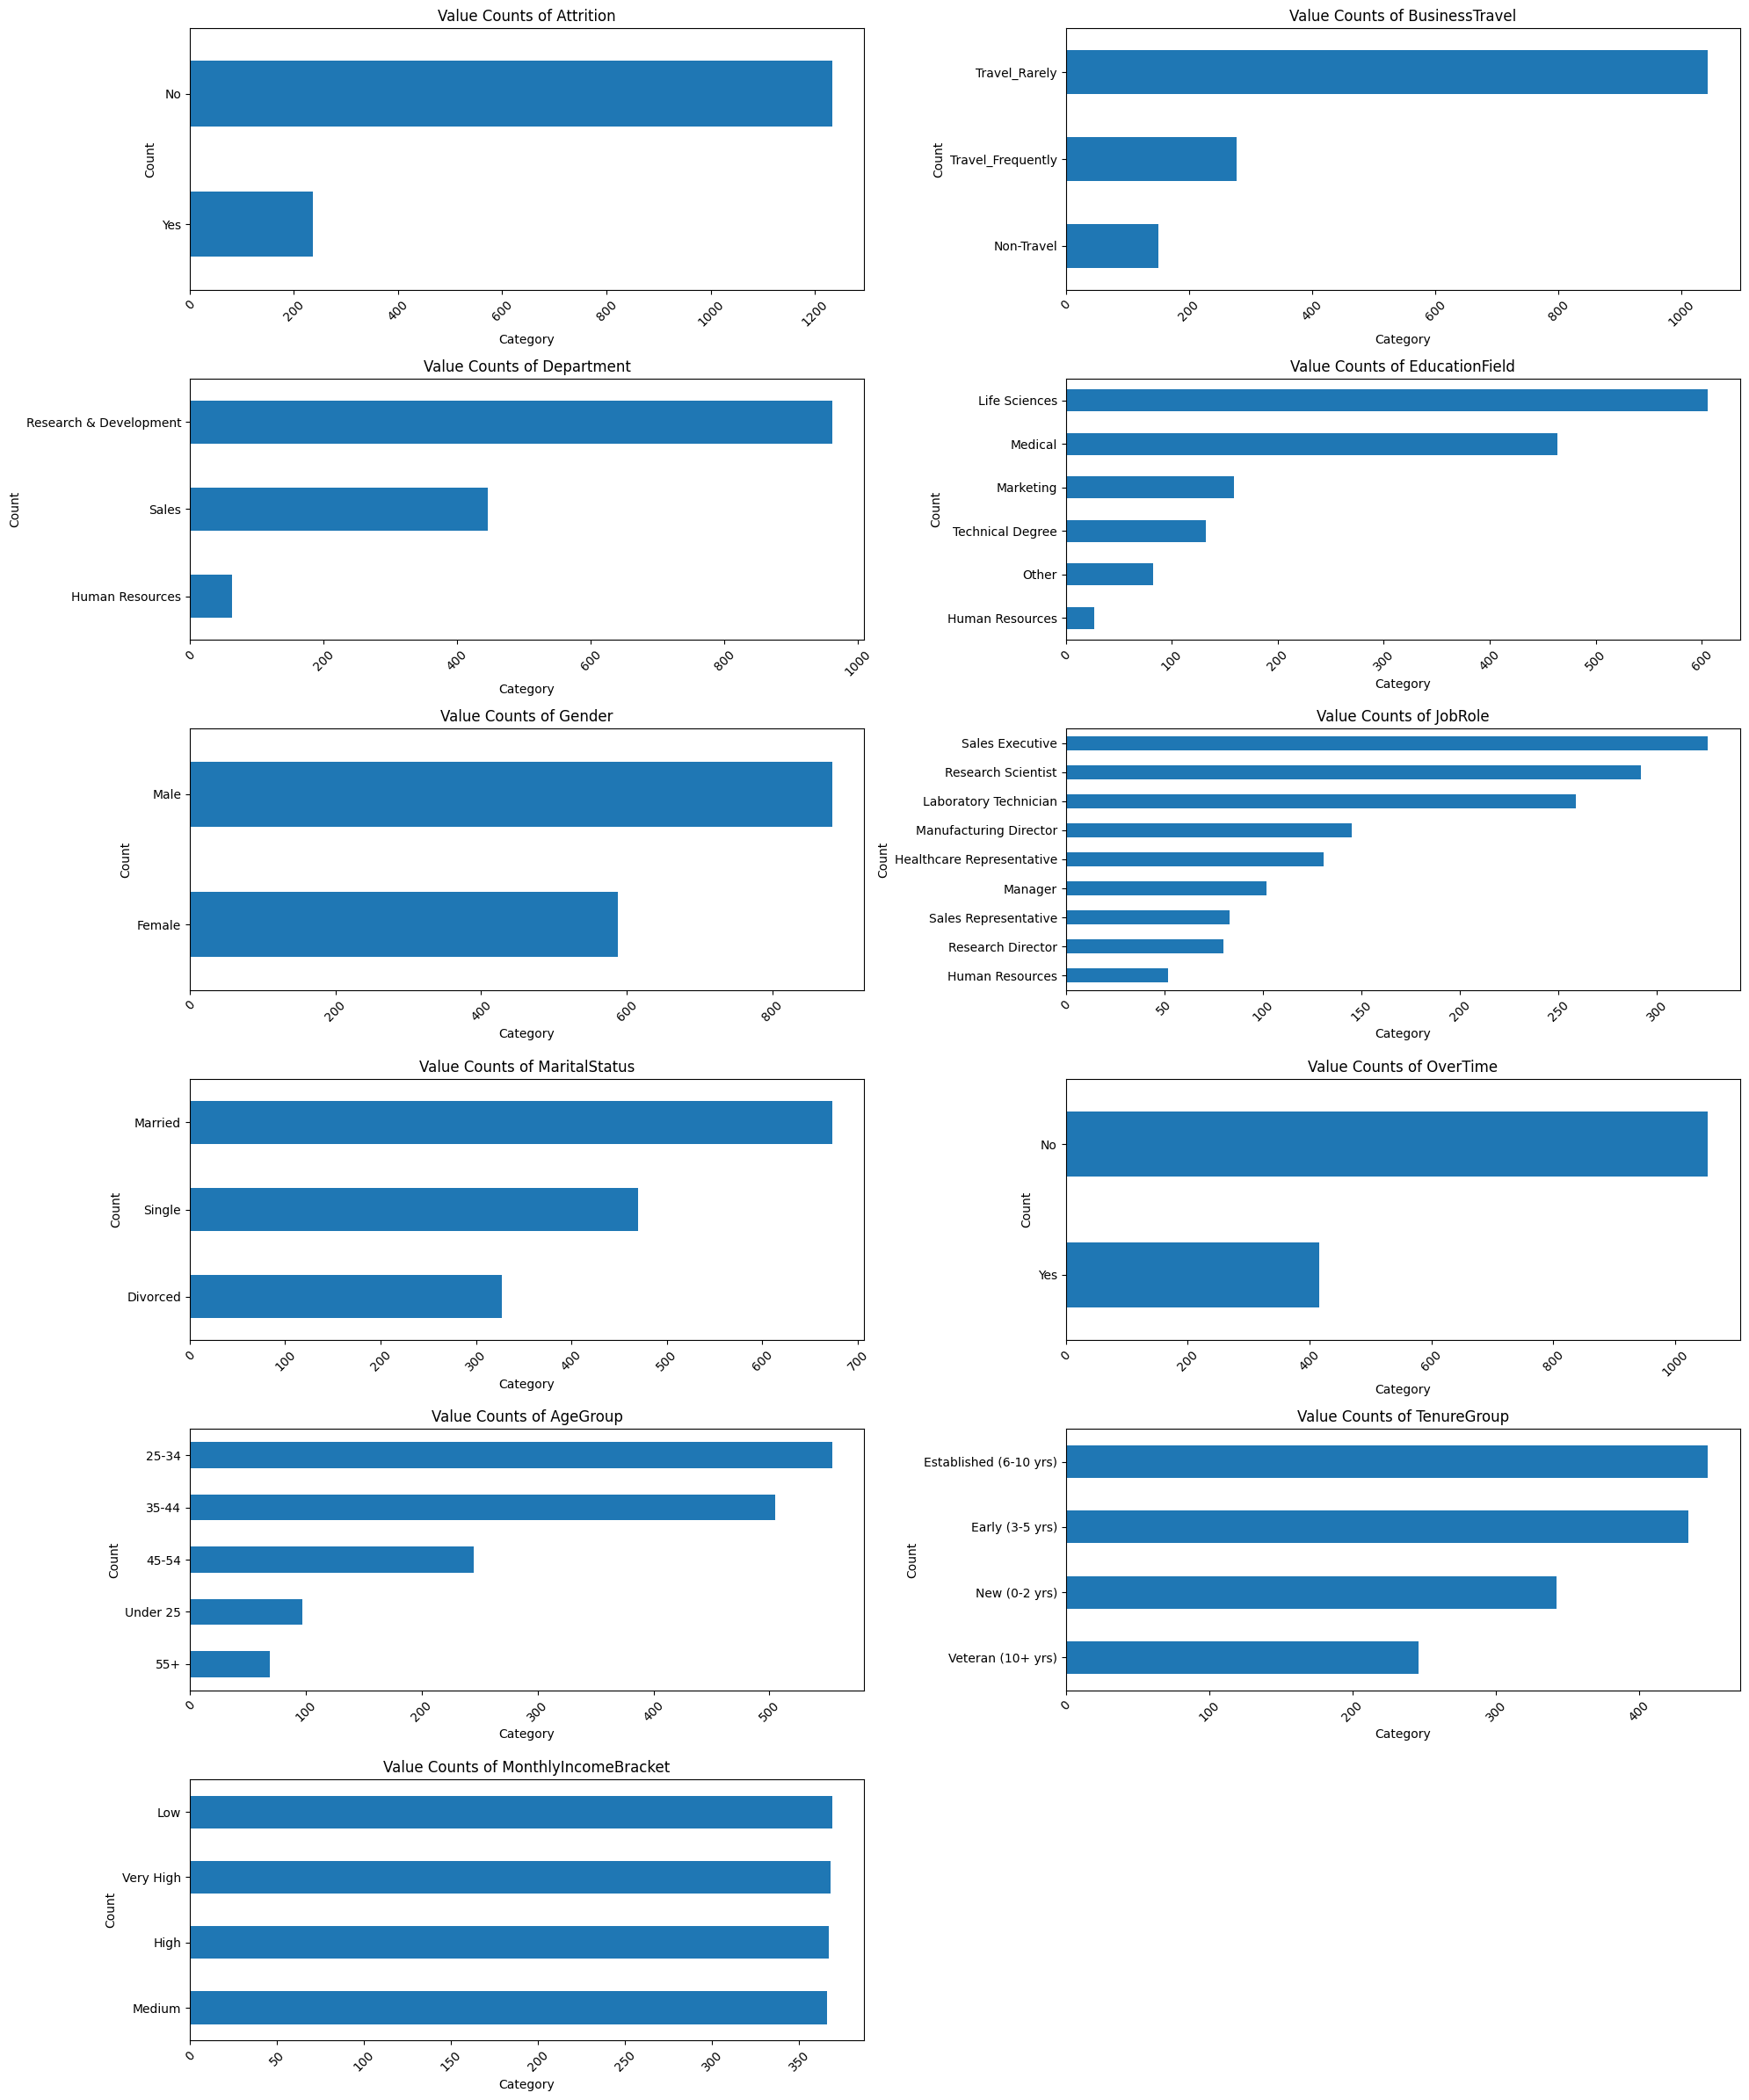

In [10]:
catcols = df.select_dtypes(include='object').columns
ncols = 2
nrows = (len(catcols) + ncols - 1) // ncols

plt.figure(figsize=(20, nrows * 4))

for i, col in enumerate(catcols):
    plt.subplot(nrows, ncols, i + 1)
    df[col].value_counts()[::-1].plot(kind='barh')
    plt.xlabel("Category")
    plt.ylabel("Count")
    plt.title(f"Value Counts of {col}")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### variable distribution

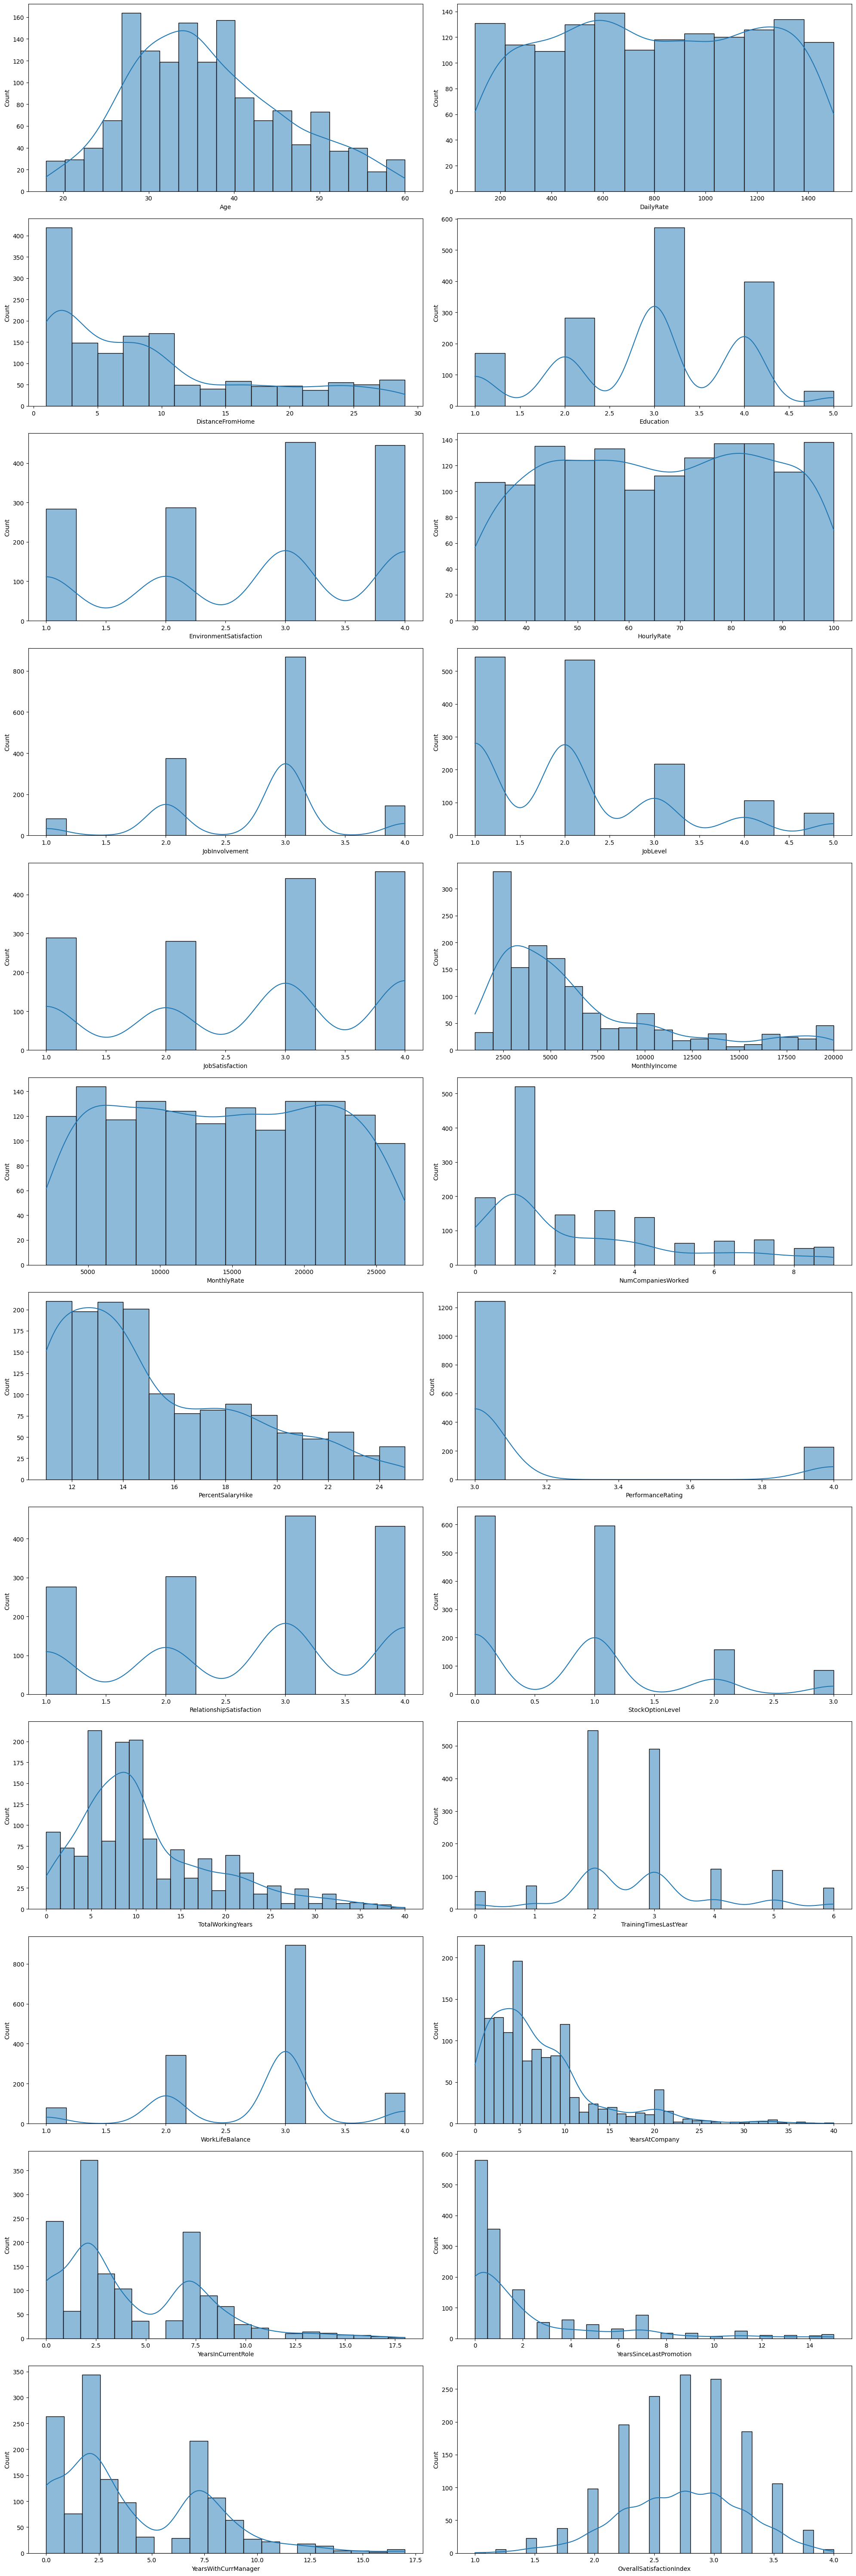

In [14]:
numcols = df.select_dtypes('number').columns
ncols = 2
nrows = (len(numcols)+ncols-1)//2

plt.figure(figsize=(20, nrows * 5))

for i,col in enumerate(numcols):
    plt.subplot(nrows, ncols, i + 1)
    sns.histplot(df[col], kde=True)

plt.tight_layout()
plt.show()

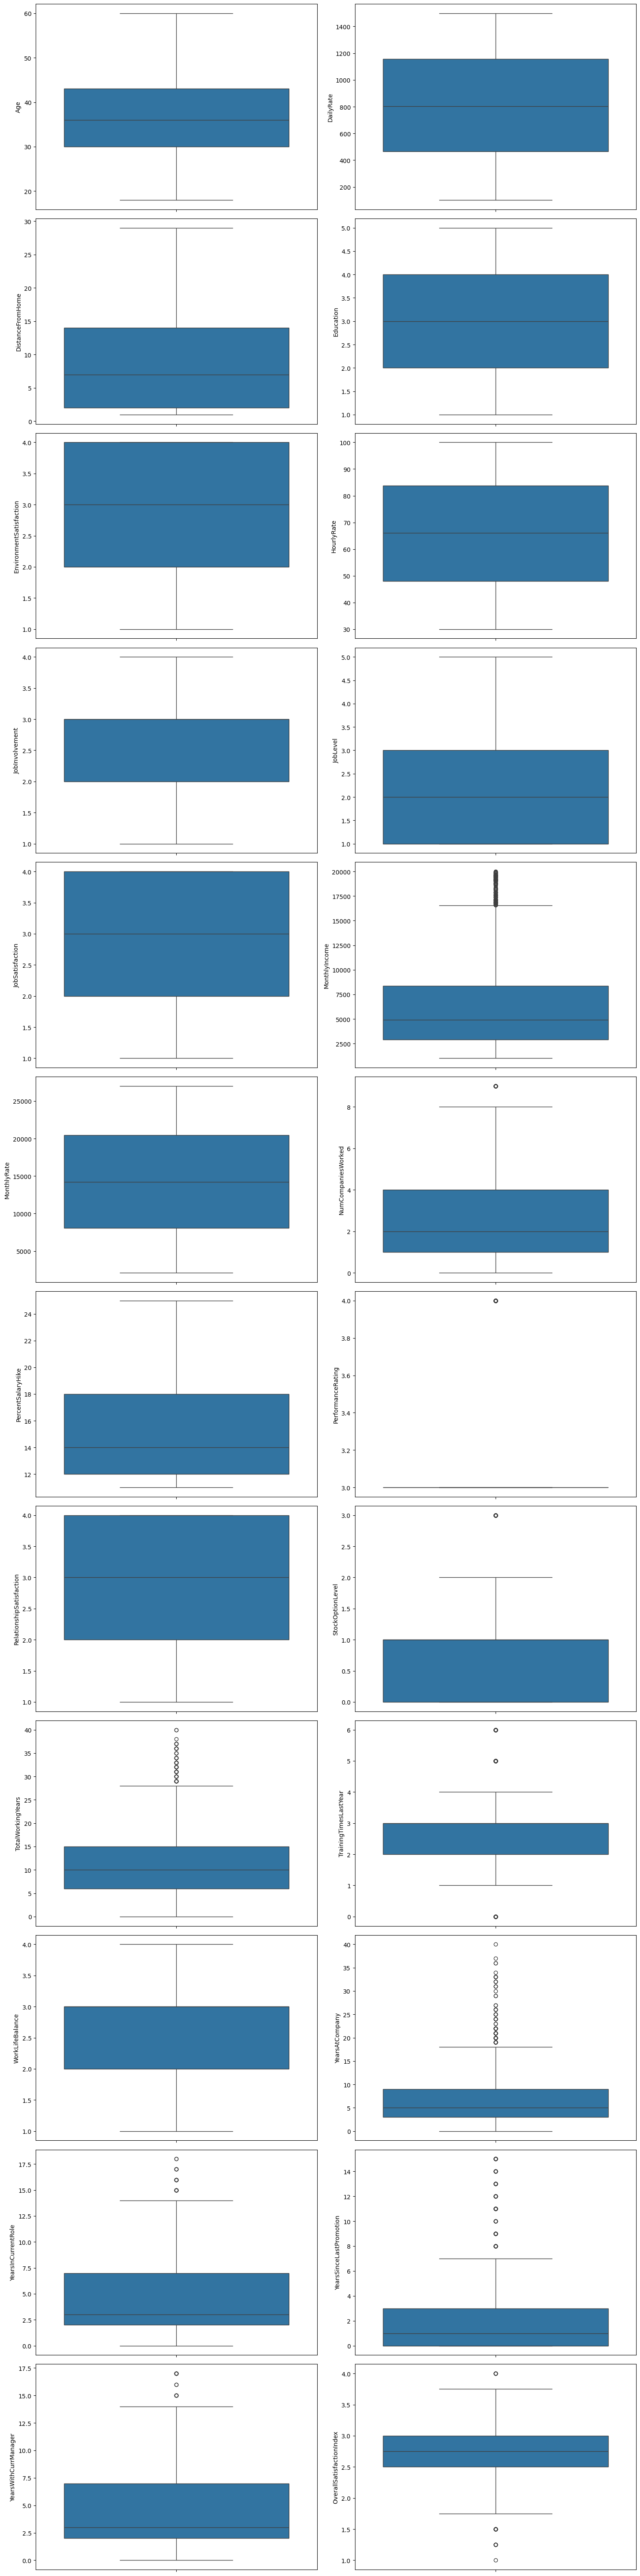

In [15]:
numcols = df.select_dtypes('number').columns
ncols = 2
nrows = (len(numcols)+ncols-1)//2

plt.figure(figsize=(15, nrows * 5))

for i,col in enumerate(numcols):
    plt.subplot(nrows, ncols, i + 1)
    sns.boxplot(df[col])

plt.tight_layout()
plt.show()

## bivariate visualization

### correlation heatmap

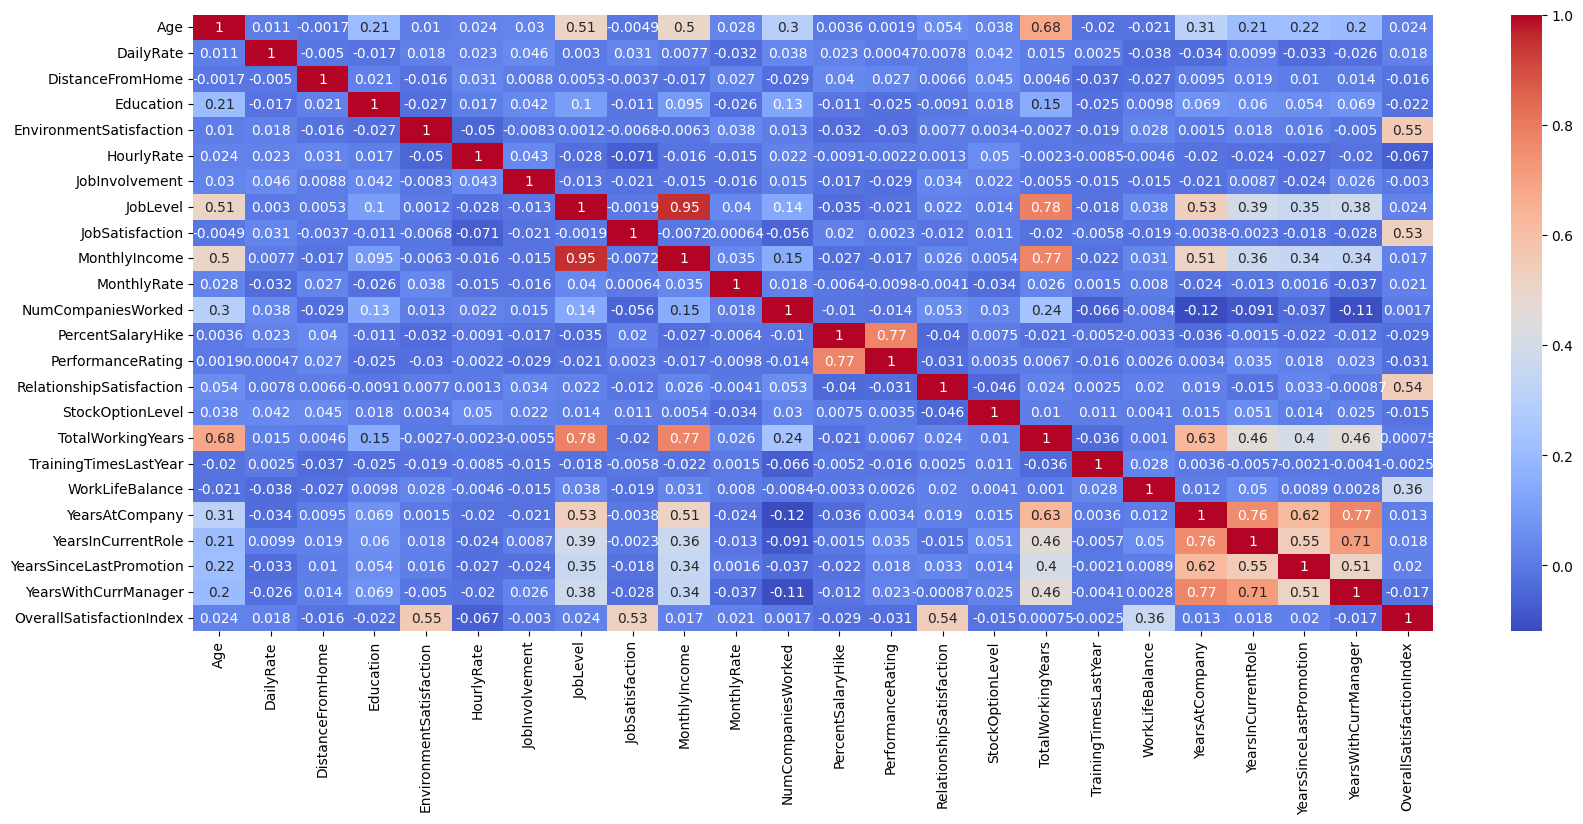

In [13]:
plt.figure(figsize=(20,8))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, cmap='coolwarm');

## dropping highly correlated columns

* drop `JobLevel` `DailyRate` `MonthlyIncome` `TotalWorkingYears` `Age` `YearsAtCompany`

In [16]:
df.drop(columns=["JobLevel", "MonthlyIncome", "TotalWorkingYears", "Age", "YearsAtCompany", "DailyRate", "MonthlyRate"], inplace=True)
numcols = df.select_dtypes(include = 'number').columns
catcols = df.select_dtypes(include = 'object').columns

# Feature Engineering

## machine-learning libraries

In [17]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder, RobustScaler, TargetEncoder, OneHotEncoder
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

## features and target

In [18]:
x = df.drop(columns=['Attrition'])
y = df['Attrition'].map({'No': 0, 'Yes': 1})

## splitting data

In [19]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.3, random_state=42, stratify=y)   # stratify ensures proportion of target values is maintained in both train and test data

# Building Prediction Model

## prediction pipeline

In [20]:
ordcols = ['BusinessTravel', 'AgeGroup', 'TenureGroup', 'MonthlyIncomeBracket']
ohecols = x.select_dtypes('object').drop(columns=ordcols).columns.tolist()

## preprocessing pipeline

In [21]:
preprocessor = ColumnTransformer(
    [
        (
            'ordinaltransformation', OrdinalEncoder(categories=[
                ["Non-Travel", "Travel_Rarely", "Travel_Frequently"],
                ["Under 25", "25-34", "35-44", "45-54", "55+"],
                ["New (0-2 yrs)", "Early (3-5 yrs)", "Established (6-10 yrs)", "Veteran (10+ yrs)"],
                ["Low", "Medium", "High", "Very High"]
            ]), ordcols
        ),
        (
            'OneHotTransformation', OneHotEncoder(drop='first', 
                                                  sparse_output=False, 
                                                  handle_unknown='ignore'), 
            ohecols
        ),
        (
            'NumericalTransformation', RobustScaler(), numcols
        )
    ], remainder='passthrough', verbose_feature_names_out=False
)

## model pipeline

In [22]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),   # add more examples of the smaller target 
    ('model', LogisticRegression(class_weight='balanced', random_state=42))
])

## hyperparameter tuning

In [23]:
param_grid = [
    {'model__solver': ['saga'],
     'model__penalty': ['l1', 'l2'],
     'model__C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0],
     'model__max_iter': [2000]},
    {'model__solver': ['lbfgs'],
     'model__penalty': ['l2'],
     'model__C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0],
     'model__max_iter': [1000]}
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

## training model

In [24]:
grid_search.fit(xtrain, ytrain)

Fitting 5 folds for each of 21 candidates, totalling 105 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"[{'model__C': [0.01, 0.05, ...], 'model__max_iter': [2000], 'model__penalty': ['l1', 'l2'], 'model__solver': ['saga']}, {'model__C': [0.01, 0.05, ...], 'model__max_iter': [1000], 'model__penalty': ['l2'], 'model__solver': ['lbfgs']}]"
,scoring,'roc_auc'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('ordinaltransformation', ...), ('OneHotTransformation', ...), ...]"


# Model Evaluation

## best model

In [25]:
print("Best Params:")

for param, val in grid_search.best_params_.items():
    print(f" {param}: {val}")

Best Params:
 model__C: 0.05
 model__max_iter: 1000
 model__penalty: l2
 model__solver: lbfgs


## evaluation results

In [26]:
print(f"\nBest Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}")


model = grid_search.best_estimator_
y_pred = model.predict(xtest)
y_probs = model.predict_proba(xtest)[:, 1]

print("\n--- Test Set Evaluation ---")
print(classification_report(ytest, y_pred))
print("Test ROC-AUC Score:", roc_auc_score(ytest, y_probs))


Best Cross-Validation ROC-AUC: 0.8379

--- Test Set Evaluation ---
              precision    recall  f1-score   support

           0       0.93      0.82      0.88       370
           1       0.43      0.69      0.53        71

    accuracy                           0.80       441
   macro avg       0.68      0.76      0.70       441
weighted avg       0.85      0.80      0.82       441

Test ROC-AUC Score: 0.8143890369242481


**Test Set Evaluation:**
- **Precision for 'No' (0)**: 0.93 - The model is good at identifying non-attriting employees.
- **Recall for 'No' (0)**: 0.82 - It correctly identifies 82% of actual non-attriting employees.
- **Precision for 'Yes' (1)**: 0.42 - When the model predicts attrition, it's correct 42% of the time. This is moderate.
- **Recall for 'Yes' (1)**: 0.69 - It correctly identifies 69% of actual attriting employees. This is a good recall for the minority class, indicating the `balanced` class weight was effective.
- **Overall Accuracy**: 0.80
- **Test ROC-AUC Score**: 0.8104 - This indicates a good ability of the model to distinguish between attriting and non-attriting employees, especially considering the class imbalance.

# Model Interpretation

## most important features

In [27]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()
coefs = model.named_steps['model'].coef_[0]

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Weight': coefs,
    'Abs_Weight': np.abs(coefs)
}).sort_values(by='Abs_Weight', ascending=False)

print("\nTop 10 Most Important Features in the Tuned Model:")
display(importance_df.head(10))


Top 10 Most Important Features in the Tuned Model:


,Feature,Weight,Abs_Weight
22,OverTime_Yes,1.163160,1.163160
21,MaritalStatus_Single,0.688247,0.688247
0,BusinessTravel,0.620867,0.620867
13,JobRole_Laboratory Technician,0.514590,0.514590
39,OverallSatisfactionIndex,-0.449422,0.449422
37,YearsSinceLastPromotion,0.430370,0.430370
3,MonthlyIncomeBracket,-0.426024,0.426024
27,JobInvolvement,-0.388320,0.388320
29,NumCompaniesWorked,0.385048,0.385048
5,Department_Sales,0.355510,0.355510


## feature importance plot

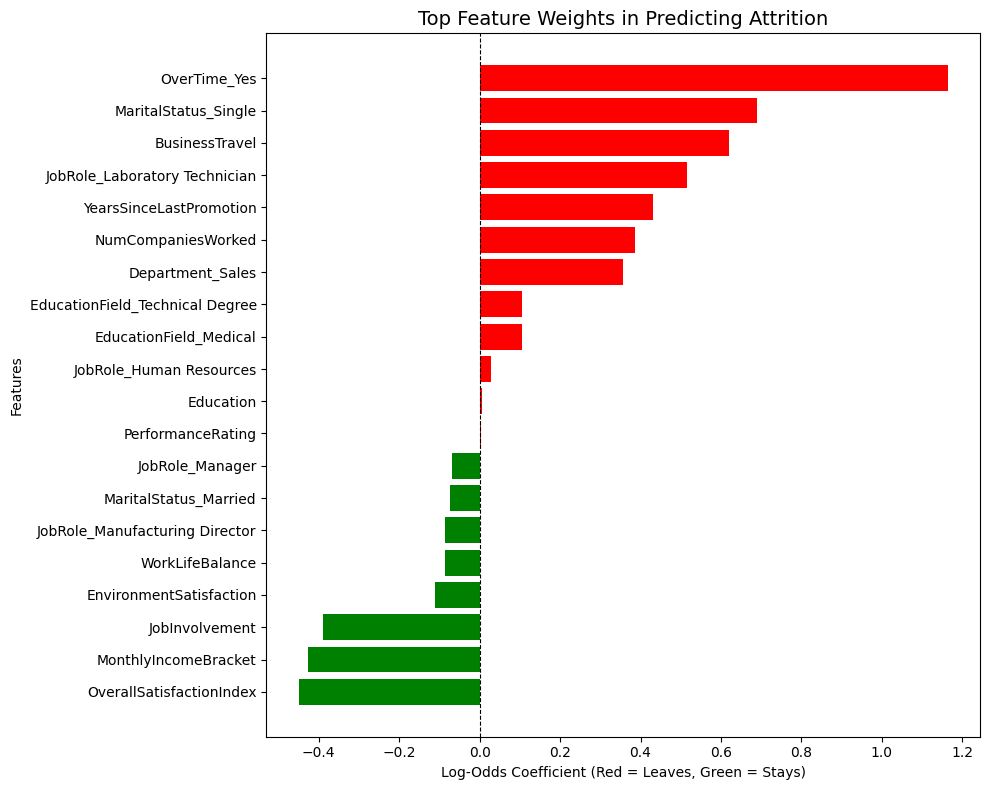

In [28]:
plt.figure(figsize=(10, 8))

top_features = pd.concat([importance_df.head(10), importance_df.tail(10)]).drop_duplicates()
top_features = top_features.sort_values(by='Weight', ascending=True)

colors = ['green' if c < 0 else 'red' for c in top_features['Weight']]

plt.barh(top_features['Feature'], top_features['Weight'], color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title("Top Feature Weights in Predicting Attrition", fontsize=14)
plt.xlabel("Log-Odds Coefficient (Red = Leaves, Green = Stays)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

# Save Model

In [29]:
import joblib

joblib.dump(model, "hr_employee_attrition.pkl")
print("model saved successfully")

model saved successfully
